<a href="https://colab.research.google.com/github/seetha-mj/Customer-Segmentation-Using-KMeans/blob/main/Copy_of_Untitled1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("online_retail_II.csv")

# Display basic information
print(df.shape)
print(df.head())
print(df.info())

# Check missing values
print(df.isnull().sum())

# Remove missing customer IDs
df = df.dropna(subset=['Customer ID'])

# Convert Customer ID into integer
df['Customer ID'] = df['Customer ID'].astype(int)

# Convert InvoiceDate into datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Remove cancelled invoices
df = df[~df['Invoice'].astype(str).str.startswith('C')]

# Remove negative and zero quantities
df = df[df['Quantity'] > 0]

# Remove zero and negative prices
df = df[df['Price'] > 0]

# Calculate total transaction value
df['TotalAmount'] = df['Quantity'] * df['Price']

# Check cleaned dataset
print(df.shape)
print(df.head())


FileNotFoundError: [Errno 2] No such file or directory: 'online_retail_II.csv'

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving online_retail_II.csv to online_retail_II.csv


In [ ]:
import pandas as pd

df = pd.read_csv('online_retail_II.csv')

print(df.shape)
df.head()

(1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [ ]:
print("Dataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

Dataset dimensions: (1067371, 8)

Column names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Missing values:
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64


In [ ]:
# Check dataset size before cleaning
print("Before cleaning:", df.shape)

# Remove rows with missing Customer IDs
df = df.dropna(subset=['Customer ID'])

# Check dataset size after cleaning
print("After cleaning:", df.shape)

# Check missing values again
print(df.isnull().sum())

Before cleaning: (1067371, 8)
After cleaning: (824364, 8)
Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
dtype: int64


In [ ]:
# Check cancelled invoices
cancelled = df['Invoice'].astype(str).str.startswith('C').sum()

# Check negative quantities
negative_qty = (df['Quantity'] < 0).sum()

# Check zero or negative prices
negative_price = (df['Price'] <= 0).sum()

print("Cancelled invoices:", cancelled)
print("Negative quantities:", negative_qty)
print("Zero or negative prices:", negative_price)

Cancelled invoices: 18744
Negative quantities: 18744
Zero or negative prices: 71


In [ ]:
print("First transaction:", df['InvoiceDate'].min())
print("Last transaction:", df['InvoiceDate'].max())

print("Number of unique customers:",
      df['Customer ID'].nunique())

print("Number of unique invoices:",
      df['Invoice'].nunique())

First transaction: 2009-12-01 07:45:00
Last transaction: 2011-12-09 12:50:00
Number of unique customers: 5942
Number of unique invoices: 44876


In [ ]:
# Remove cancelled invoices
df = df[~df['Invoice'].astype(str).str.startswith('C')]

# Remove negative and zero quantities
df = df[df['Quantity'] > 0]

# Remove zero and negative prices
df = df[df['Price'] > 0]

# Reset index
df = df.reset_index(drop=True)

# Check the cleaned dataset
print("Dataset after cleaning:", df.shape)

print("Cancelled invoices remaining:",
      df['Invoice'].astype(str).str.startswith('C').sum())

print("Negative quantities remaining:",
      (df['Quantity'] < 0).sum())

print("Non-positive prices remaining:",
      (df['Price'] <= 0).sum())

Dataset after cleaning: (805549, 8)
Cancelled invoices remaining: 0
Negative quantities remaining: 0
Non-positive prices remaining: 0


In [ ]:
# Calculate total purchase value
df['TotalAmount'] = df['Quantity'] * df['Price']

# Display the results
print(df[['Quantity', 'Price', 'TotalAmount']].head())

   Quantity  Price  TotalAmount
0        12   6.95         83.4
1        12   6.75         81.0
2        12   6.75         81.0
3        48   2.10        100.8
4        24   1.25         30.0


In [ ]:
print("Final dataset dimensions:", df.shape)

print("Number of unique customers:",
      df['Customer ID'].nunique())

print("Number of unique invoices:",
      df['Invoice'].nunique())

print("Total sales value:",
      df['TotalAmount'].sum())

Final dataset dimensions: (805549, 9)
Number of unique customers: 5878
Number of unique invoices: 36969
Total sales value: 17743429.178000003


In [ ]:
# Descriptive statistics
print(df[['Quantity', 'Price', 'TotalAmount']].describe())

            Quantity          Price    TotalAmount
count  805549.000000  805549.000000  805549.000000
mean       13.290522       3.206561      22.026505
std       143.634088      29.199173     224.041928
min         1.000000       0.001000       0.001000
25%         2.000000       1.250000       4.950000
50%         5.000000       1.950000      11.850000
75%        12.000000       3.750000      19.500000
max     80995.000000   10953.500000  168469.600000


In [ ]:
# Count unique customers by country
country_customers = df.groupby('Country')['Customer ID'].nunique()

# Display top 10 countries
country_customers = country_customers.sort_values(ascending=False)

print(country_customers.head(10))

Country
United Kingdom    5350
Germany            107
France              95
Spain               41
Belgium             29
Portugal            24
Switzerland         22
Netherlands         22
Sweden              19
Italy               17
Name: Customer ID, dtype: int64


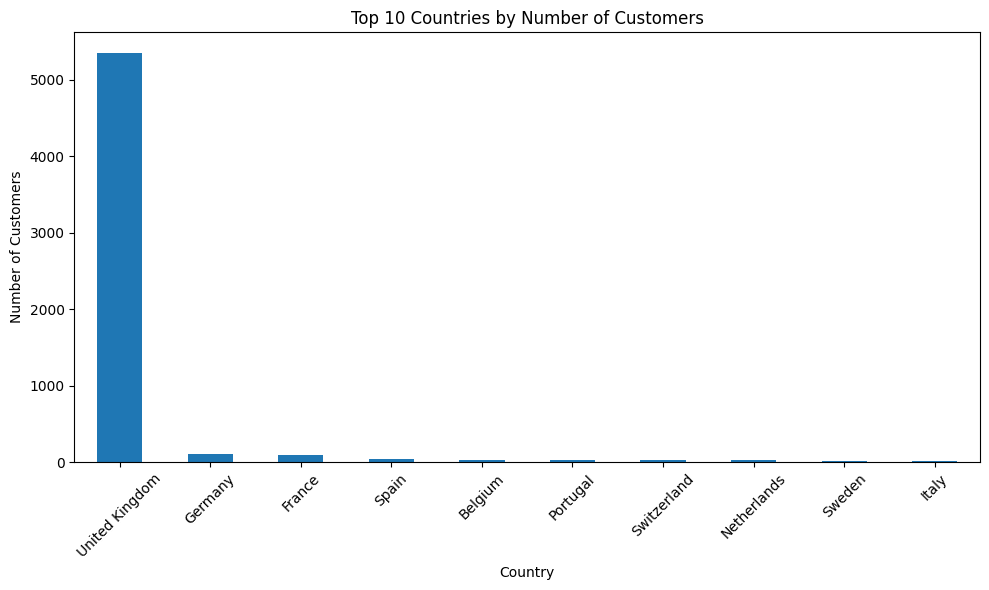

In [ ]:
plt.figure(figsize=(10,6))

country_customers.head(10).plot(kind='bar')

plt.title('Top 10 Countries by Number of Customers')
plt.xlabel('Country')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
country_sales = df.groupby('Country')['TotalAmount'].sum()

country_sales = country_sales.sort_values(ascending=False)

print(country_sales.head(10))

Country
United Kingdom    1.472315e+07
EIRE              6.216311e+05
Netherlands       5.542323e+05
Germany           4.312625e+05
France            3.552575e+05
Australia         1.699681e+05
Spain             1.091785e+05
Switzerland       1.003653e+05
Sweden            9.154972e+04
Denmark           6.986219e+04
Name: TotalAmount, dtype: float64


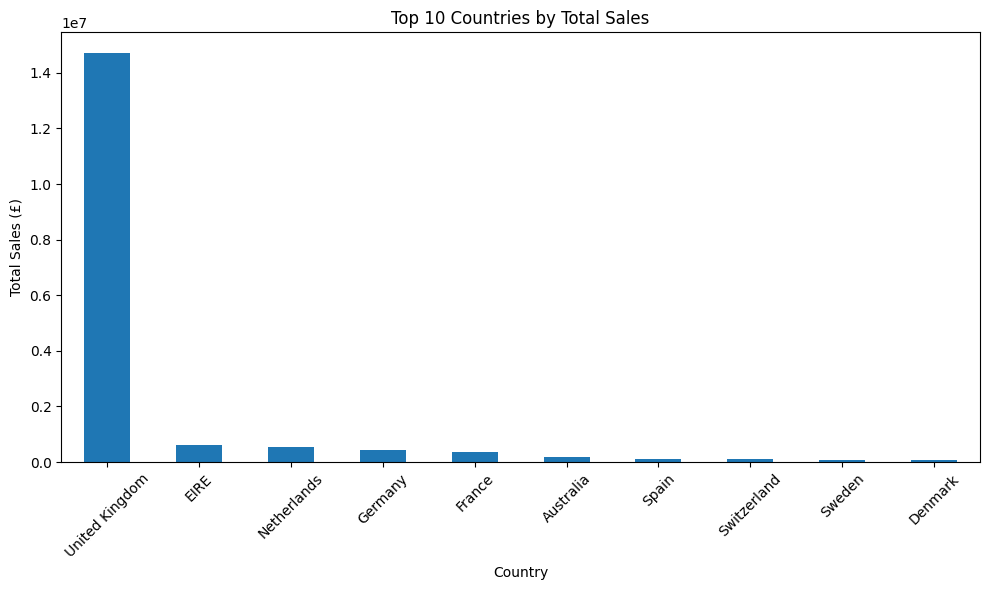

In [ ]:
plt.figure(figsize=(10,6))

country_sales.head(10).plot(kind='bar')

plt.title('Top 10 Countries by Total Sales')
plt.xlabel('Country')
plt.ylabel('Total Sales (£)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Extract year and month
df['YearMonth'] = df['InvoiceDate'].dt.to_period('M')

# Calculate monthly sales
monthly_sales = df.groupby('YearMonth')['TotalAmount'].sum()

# Plot monthly sales
plt.figure(figsize=(14,6))

monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales (£)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

AttributeError: Can only use .dt accessor with datetimelike values

In [ ]:
# Convert InvoiceDate into datetime format
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], errors='coerce')

# Check the data type
print(df['InvoiceDate'].dtype)

# Check if any dates failed to convert
print("Missing dates:", df['InvoiceDate'].isnull().sum())

datetime64[ns]
Missing dates: 0


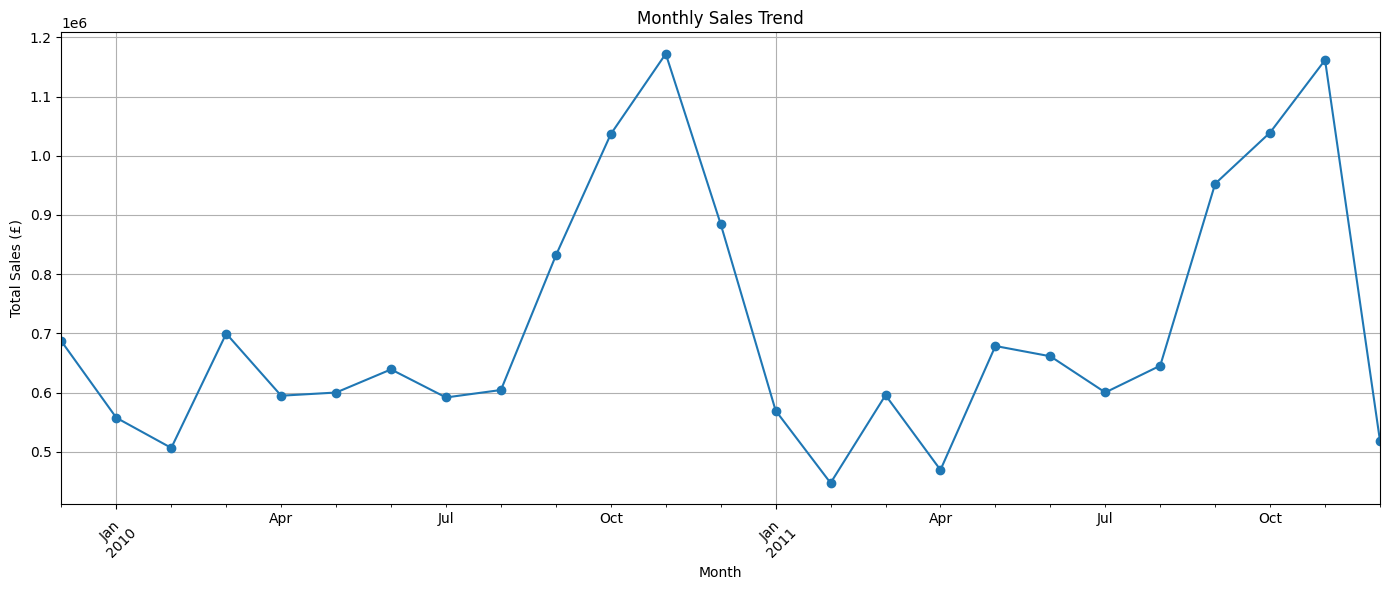

In [ ]:
# Extract year and month
df['YearMonth'] = df['InvoiceDate'].dt.to_period('M')

# Calculate monthly sales
monthly_sales = df.groupby('YearMonth')['TotalAmount'].sum()

# Plot monthly sales
plt.figure(figsize=(14,6))

monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales (£)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Set reference date
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

# Calculate RFM values for each customer
rfm = df.groupby('Customer ID').agg({

    'InvoiceDate': lambda x: (reference_date - x.max()).days,

    'Invoice': 'nunique',

    'TotalAmount': 'sum'

})

# Rename columns
rfm.columns = ['Recency', 'Frequency', 'Monetary']

# Display first five customers
print(rfm.head())

             Recency  Frequency  Monetary
Customer ID                              
12346.0          326         12  77556.46
12347.0            2          8   5633.32
12348.0           75          5   2019.40
12349.0           19          4   4428.69
12350.0          310          1    334.40


In [ ]:
print("RFM dataset dimensions:", rfm.shape)

print("\nRFM descriptive statistics:")
print(rfm.describe())

print("\nMissing values:")
print(rfm.isnull().sum())

RFM dataset dimensions: (5878, 3)

RFM descriptive statistics:
           Recency    Frequency       Monetary
count  5878.000000  5878.000000    5878.000000
mean    201.331916     6.289384    3018.616737
std     209.338707    13.009406   14737.731040
min       1.000000     1.000000       2.950000
25%      26.000000     1.000000     348.762500
50%      96.000000     3.000000     898.915000
75%     380.000000     7.000000    2307.090000
max     739.000000   398.000000  608821.650000

Missing values:
Recency      0
Frequency    0
Monetary     0
dtype: int64


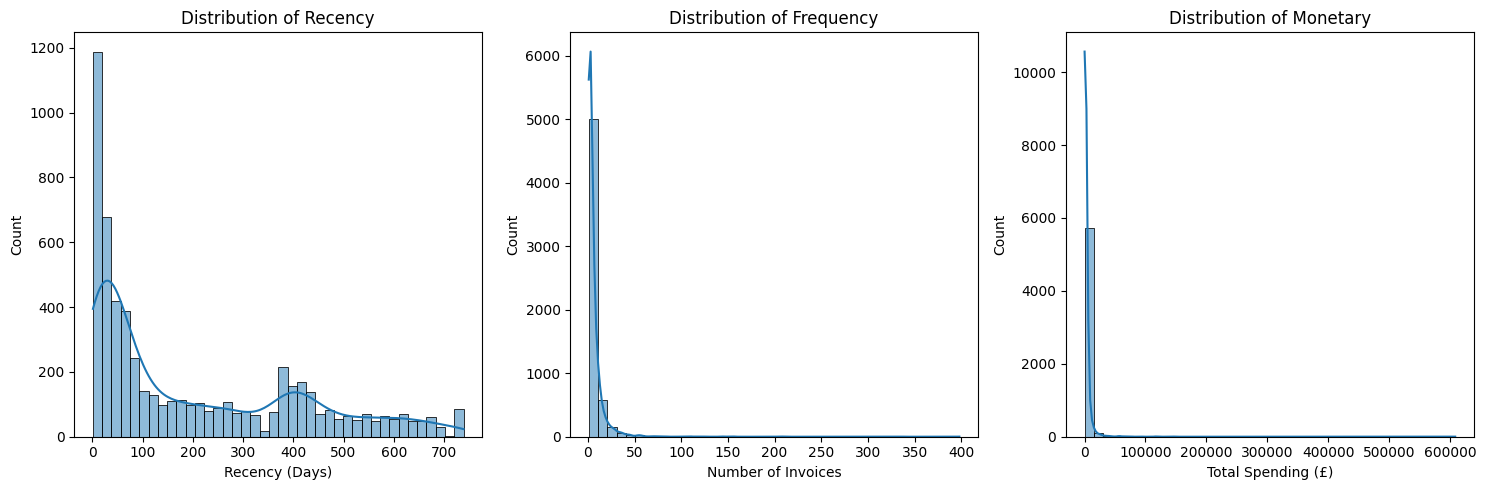

In [ ]:
# Plot RFM distributions

plt.figure(figsize=(15, 5))

# Recency distribution
plt.subplot(1, 3, 1)
sns.histplot(rfm['Recency'], bins=40, kde=True)
plt.title('Distribution of Recency')
plt.xlabel('Recency (Days)')

# Frequency distribution
plt.subplot(1, 3, 2)
sns.histplot(rfm['Frequency'], bins=40, kde=True)
plt.title('Distribution of Frequency')
plt.xlabel('Number of Invoices')

# Monetary distribution
plt.subplot(1, 3, 3)
sns.histplot(rfm['Monetary'], bins=40, kde=True)
plt.title('Distribution of Monetary')
plt.xlabel('Total Spending (£)')

plt.tight_layout()
plt.show()

In [ ]:
print("Skewness of RFM variables:")
print(rfm.skew())

Skewness of RFM variables:
Recency       0.887198
Frequency    12.639951
Monetary     25.314235
dtype: float64


In [ ]:
# Create a copy of RFM data
rfm_log = rfm.copy()

# Apply logarithmic transformation
rfm_log = np.log1p(rfm_log)

# Display descriptive statistics
print(rfm_log.describe())

# Calculate skewness after transformation
print("\nSkewness after log transformation:")
print(rfm_log.skew())

           Recency    Frequency     Monetary
count  5878.000000  5878.000000  5878.000000
mean      4.454132     1.549588     6.836550
std       1.559404     0.809447     1.387864
min       0.693147     0.693147     1.373716
25%       3.295837     0.693147     5.857254
50%       4.574711     1.386294     6.802300
75%       5.942799     2.079442     7.744175
max       6.606650     5.988961    13.319282

Skewness after log transformation:
Recency     -0.488631
Frequency    1.001471
Monetary     0.265113
dtype: float64


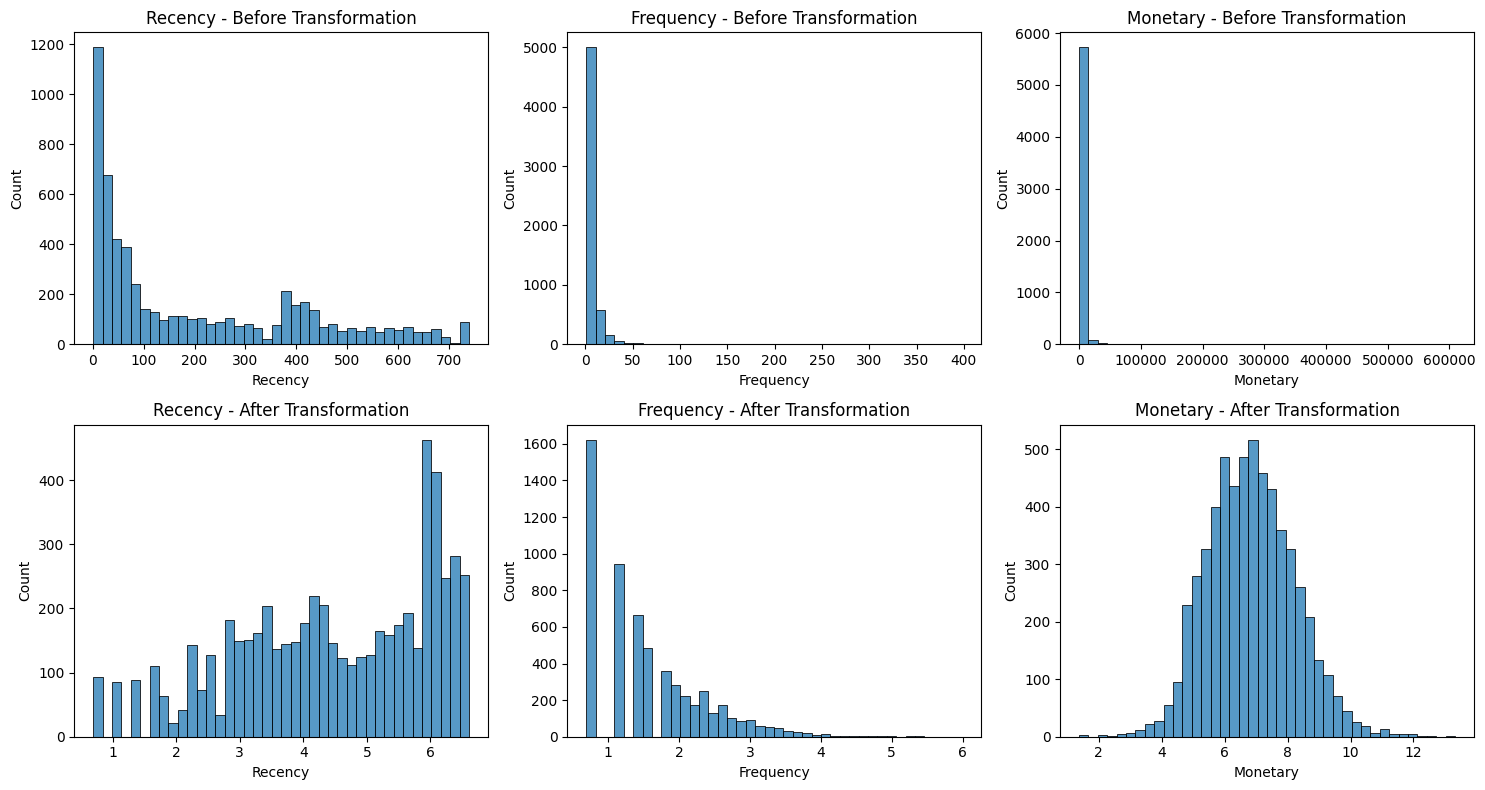

In [ ]:
# Compare distributions before and after transformation

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

variables = ['Recency', 'Frequency', 'Monetary']

for i, col in enumerate(variables):

    sns.histplot(rfm[col], bins=40, ax=axes[0, i])
    axes[0, i].set_title(col + ' - Before Transformation')

    sns.histplot(rfm_log[col], bins=40, ax=axes[1, i])
    axes[1, i].set_title(col + ' - After Transformation')

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler

# Initialise StandardScaler
scaler = StandardScaler()

# Standardise the transformed RFM data
rfm_scaled = scaler.fit_transform(rfm_log)

# Convert into a DataFrame
rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=['Recency', 'Frequency', 'Monetary'],
    index=rfm.index
)

# Display first five observations
print(rfm_scaled.head())

# Check mean and standard deviation
print("\nMean:")
print(rfm_scaled.mean())

print("\nStandard deviation:")
print(rfm_scaled.std())

              Recency  Frequency  Monetary
Customer ID                               
12346.0      0.856701   1.254496  3.186625
12347.0     -2.151979   0.800166  1.297127
12348.0     -0.079138   0.299207  0.558100
12349.0     -0.935308   0.073946  1.123790
12350.0      0.824527  -1.058146 -0.735888

Mean:
Recency     -5.077032e-16
Frequency    1.885755e-16
Monetary    -4.351742e-16
dtype: float64

Standard deviation:
Recency      1.000085
Frequency    1.000085
Monetary     1.000085
dtype: float64


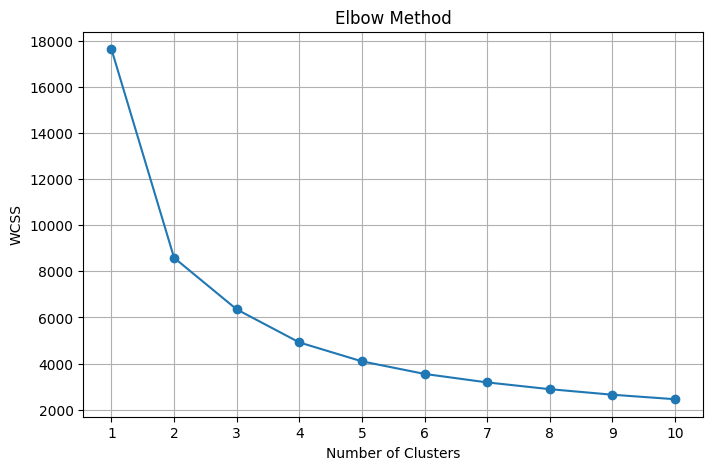

In [ ]:
from sklearn.cluster import KMeans

wcss = []

for i in range(1, 11):

    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)

    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker='o')

plt.title('Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.xticks(range(1, 11))
plt.grid(True)

plt.show()

Clusters: 2 | Silhouette Score: 0.4343
Clusters: 3 | Silhouette Score: 0.3458
Clusters: 4 | Silhouette Score: 0.3649
Clusters: 5 | Silhouette Score: 0.3462
Clusters: 6 | Silhouette Score: 0.3354
Clusters: 7 | Silhouette Score: 0.3075
Clusters: 8 | Silhouette Score: 0.2925
Clusters: 9 | Silhouette Score: 0.2864
Clusters: 10 | Silhouette Score: 0.2856


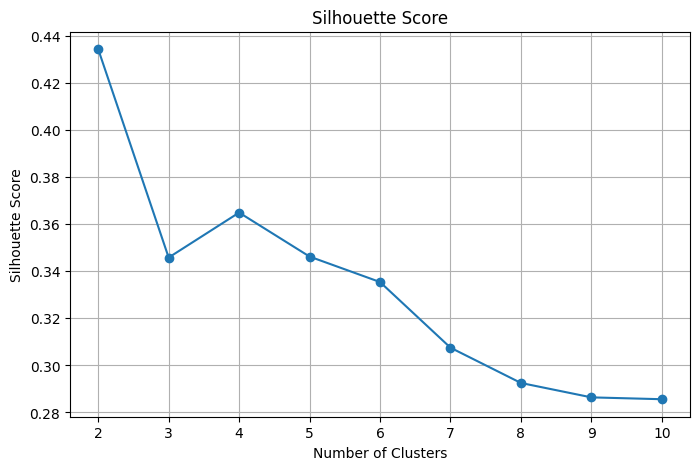

In [ ]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for i in range(2, 11):

    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(rfm_scaled)

    score = silhouette_score(
        rfm_scaled,
        labels,
        sample_size=2000,
        random_state=42
    )

    silhouette_scores.append(score)

    print("Clusters:", i,
          "| Silhouette Score:", round(score, 4))

plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), silhouette_scores, marker='o')

plt.title('Silhouette Score')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

In [ ]:
# K-Means with 2 clusters
kmeans_2 = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

rfm_2 = rfm.copy()
rfm_2['Cluster'] = kmeans_2.fit_predict(rfm_scaled)

# K-Means with 4 clusters
kmeans_4 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
)

rfm_4 = rfm.copy()
rfm_4['Cluster'] = kmeans_4.fit_predict(rfm_scaled)


# Display cluster sizes
print("CLUSTER SIZES - 2 CLUSTERS")
print(rfm_2['Cluster'].value_counts().sort_index())

print("\nCLUSTER SIZES - 4 CLUSTERS")
print(rfm_4['Cluster'].value_counts().sort_index())

CLUSTER SIZES - 2 CLUSTERS
Cluster
0    2322
1    3556
Name: count, dtype: int64

CLUSTER SIZES - 4 CLUSTERS
Cluster
0    1188
1    1974
2    1465
3    1251
Name: count, dtype: int64


In [ ]:
# Median RFM values for 2 clusters
print("CUSTOMER PROFILES - 2 CLUSTERS")

print(
    rfm_2.groupby('Cluster')[
        ['Recency', 'Frequency', 'Monetary']
    ].median()
)

# Median RFM values for 4 clusters
print("\nCUSTOMER PROFILES - 4 CLUSTERS")

print(
    rfm_4.groupby('Cluster')[
        ['Recency', 'Frequency', 'Monetary']
    ].median()
)

CUSTOMER PROFILES - 2 CLUSTERS
         Recency  Frequency  Monetary
Cluster                              
0           23.0        8.0   2905.10
1          290.0        2.0    422.59

CUSTOMER PROFILES - 4 CLUSTERS
         Recency  Frequency  Monetary
Cluster                              
0           16.5       13.0   5126.80
1          404.0        1.0    283.58
2          185.0        5.0   1509.04
3           24.0        3.0    743.17


In [ ]:
# Build the final K-Means model
final_kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
)

# Assign cluster labels
rfm['Cluster'] = final_kmeans.fit_predict(rfm_scaled)

# Create meaningful customer segment names
cluster_names = {
    0: 'High-Value Active Customers',
    1: 'Inactive Customers',
    2: 'Occasional Customers',
    3: 'Recent Low-Spending Customers'
}

rfm['Customer_Segment'] = rfm['Cluster'].map(cluster_names)

# Display first 10 customers
print(rfm.head(10))

             Recency  Frequency  Monetary  Cluster  \
Customer ID                                          
12346.0          326         12  77556.46        0   
12347.0            2          8   5633.32        0   
12348.0           75          5   2019.40        2   
12349.0           19          4   4428.69        3   
12350.0          310          1    334.40        1   
12351.0          375          1    300.93        1   
12352.0           36         10   2849.84        0   
12353.0          204          2    406.76        1   
12354.0          232          1   1079.40        1   
12355.0          214          2    947.61        2   

                          Customer_Segment  
Customer ID                                 
12346.0        High-Value Active Customers  
12347.0        High-Value Active Customers  
12348.0               Occasional Customers  
12349.0      Recent Low-Spending Customers  
12350.0                 Inactive Customers  
12351.0                 Inactive Cus

In [ ]:
# Calculate customer segment summary
segment_summary = rfm.groupby('Customer_Segment').agg(
    Customers=('Recency', 'count'),
    Average_Recency=('Recency', 'median'),
    Average_Frequency=('Frequency', 'median'),
    Average_Monetary=('Monetary', 'median')
)

# Calculate percentage of customers
segment_summary['Percentage'] = (
    segment_summary['Customers'] / len(rfm) * 100
)

print(segment_summary.round(2))

                               Customers  Average_Recency  Average_Frequency  \
Customer_Segment                                                               
High-Value Active Customers         1188             16.5               13.0   
Inactive Customers                  1974            404.0                1.0   
Occasional Customers                1465            185.0                5.0   
Recent Low-Spending Customers       1251             24.0                3.0   

                               Average_Monetary  Percentage  
Customer_Segment                                             
High-Value Active Customers             5126.80       20.21  
Inactive Customers                       283.58       33.58  
Occasional Customers                    1509.04       24.92  
Recent Low-Spending Customers            743.17       21.28  


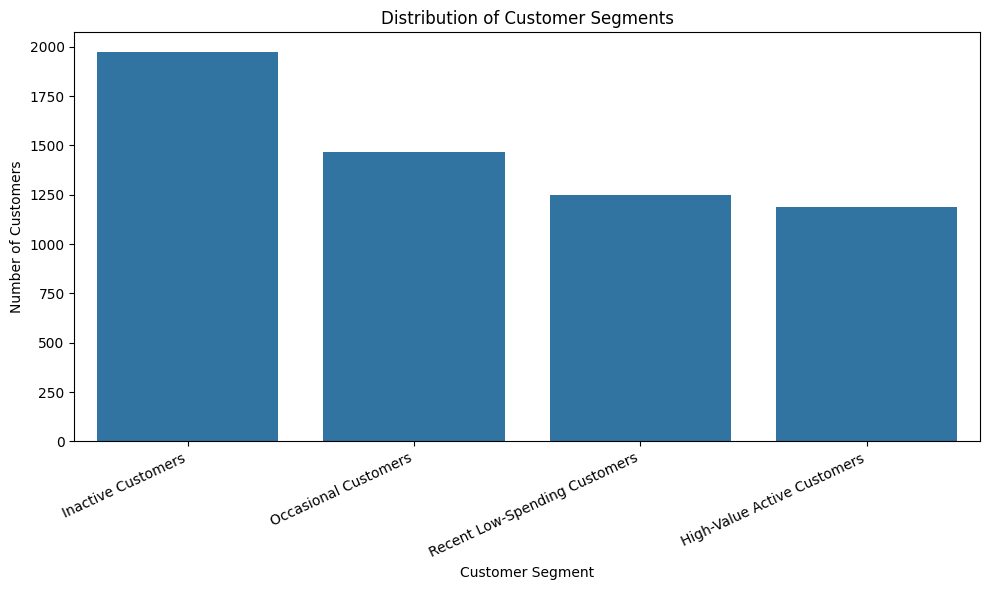

In [ ]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=rfm,
    x='Customer_Segment',
    order=rfm['Customer_Segment'].value_counts().index
)

plt.title('Distribution of Customer Segments')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

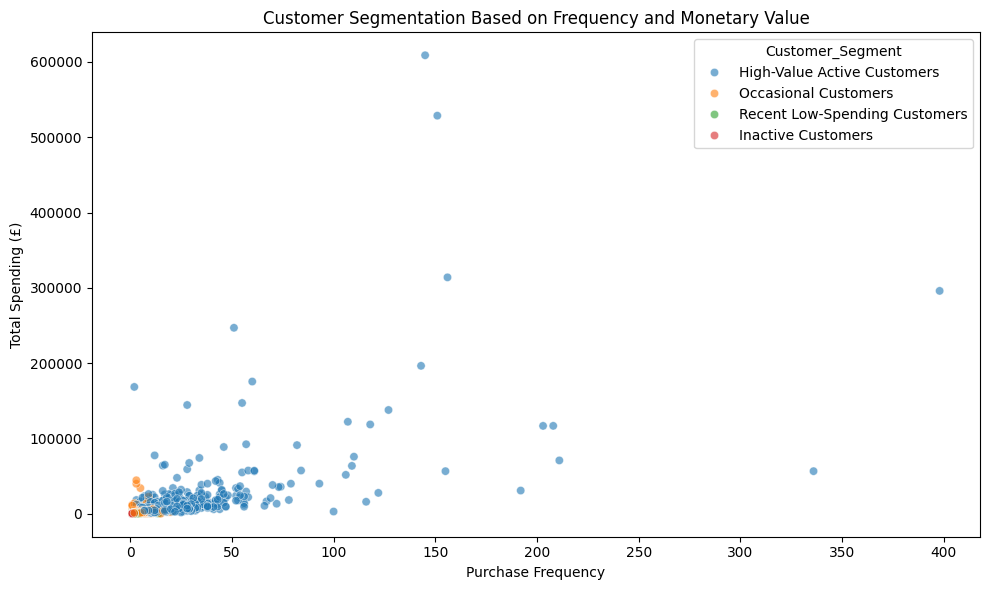

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x='Frequency',
    y='Monetary',
    hue='Customer_Segment',
    alpha=0.6
)

plt.title('Customer Segmentation Based on Frequency and Monetary Value')
plt.xlabel('Purchase Frequency')
plt.ylabel('Total Spending (£)')
plt.tight_layout()
plt.show()

In [ ]:
segment_summary = rfm.groupby('Customer_Segment').agg(
    Customers=('Recency', 'count'),
    Median_Recency=('Recency', 'median'),
    Median_Frequency=('Frequency', 'median'),
    Median_Monetary=('Monetary', 'median')
)

segment_summary['Percentage'] = (
    segment_summary['Customers'] / len(rfm) * 100
)

print(segment_summary.round(2))

                               Customers  Median_Recency  Median_Frequency  \
Customer_Segment                                                             
High-Value Active Customers         1188            16.5              13.0   
Inactive Customers                  1974           404.0               1.0   
Occasional Customers                1465           185.0               5.0   
Recent Low-Spending Customers       1251            24.0               3.0   

                               Median_Monetary  Percentage  
Customer_Segment                                            
High-Value Active Customers            5126.80       20.21  
Inactive Customers                      283.58       33.58  
Occasional Customers                   1509.04       24.92  
Recent Low-Spending Customers           743.17       21.28  


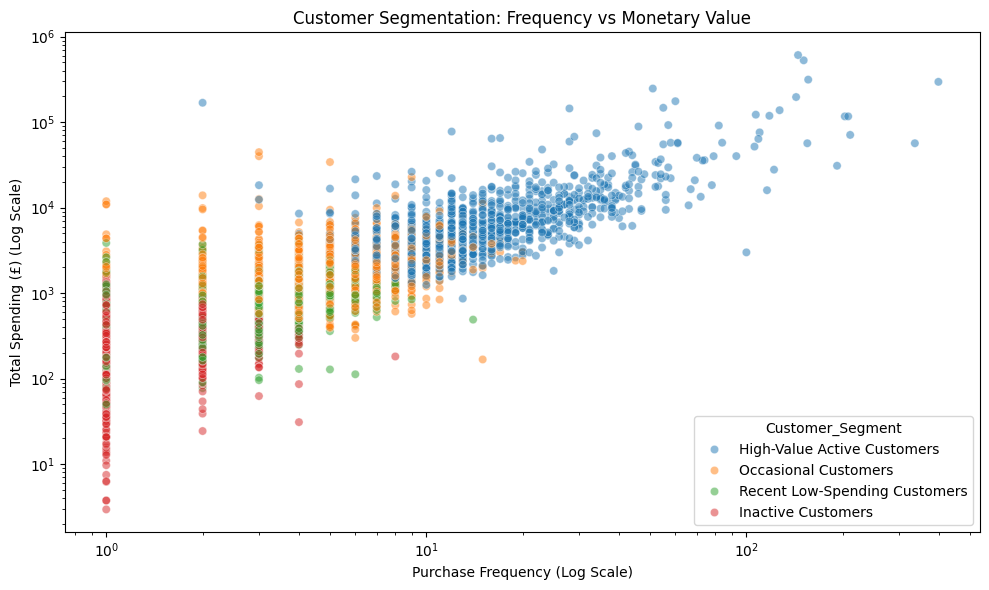

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x='Frequency',
    y='Monetary',
    hue='Customer_Segment',
    alpha=0.5
)

plt.xscale('log')
plt.yscale('log')

plt.title('Customer Segmentation: Frequency vs Monetary Value')
plt.xlabel('Purchase Frequency (Log Scale)')
plt.ylabel('Total Spending (£) (Log Scale)')

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Evaluate final K-Means model

sil_score = silhouette_score(
    rfm_scaled,
    rfm['Cluster'],
    sample_size=2000,
    random_state=42
)

db_score = davies_bouldin_score(
    rfm_scaled,
    rfm['Cluster']
)

ch_score = calinski_harabasz_score(
    rfm_scaled,
    rfm['Cluster']
)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print("Silhouette Score:", round(sil_score, 4))
print("Davies-Bouldin Index:", round(db_score, 4))
print("Calinski-Harabasz Index:", round(ch_score, 2))

MODEL EVALUATION RESULTS
------------------------
Silhouette Score: 0.3649
Davies-Bouldin Index: 0.9303
Calinski-Harabasz Index: 5061.72


In [ ]:
# Calculate median RFM values for each cluster

cluster_profile = rfm.groupby('Cluster')[
    ['Recency', 'Frequency', 'Monetary']
].median()

print(cluster_profile)

         Recency  Frequency  Monetary
Cluster                              
0           16.5       13.0   5126.80
1          404.0        1.0    283.58
2          185.0        5.0   1509.04
3           24.0        3.0    743.17


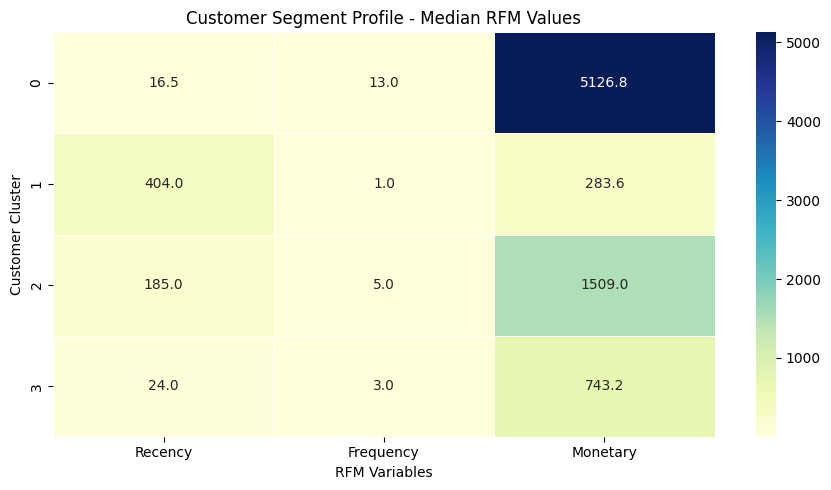

In [ ]:
plt.figure(figsize=(9, 5))

sns.heatmap(
    cluster_profile,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu',
    linewidths=0.5
)

plt.title('Customer Segment Profile - Median RFM Values')
plt.xlabel('RFM Variables')
plt.ylabel('Customer Cluster')

plt.tight_layout()
plt.show()

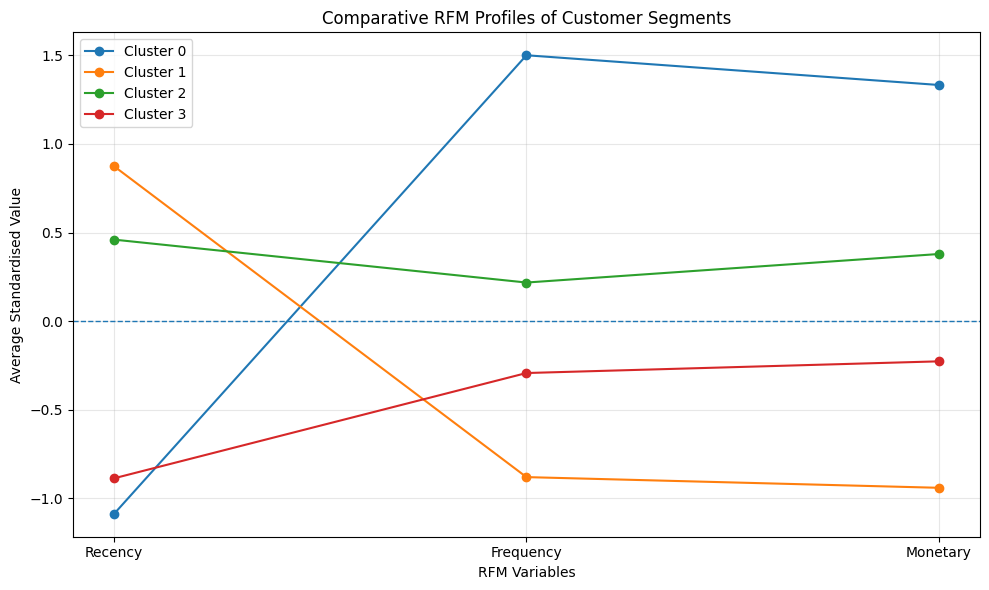

In [ ]:
# Standardised customer profiles

profile_scaled = (
    rfm_scaled.assign(Cluster=rfm['Cluster'])
    .groupby('Cluster')
    .mean()
)

plt.figure(figsize=(10, 6))

for cluster in profile_scaled.index:

    plt.plot(
        profile_scaled.columns,
        profile_scaled.loc[cluster],
        marker='o',
        label=f'Cluster {cluster}'
    )

plt.axhline(0, linestyle='--', linewidth=1)

plt.title('Comparative RFM Profiles of Customer Segments')
plt.xlabel('RFM Variables')
plt.ylabel('Average Standardised Value')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
final_summary = rfm.groupby('Customer_Segment').agg(
    Number_of_Customers=('Recency', 'count'),
    Median_Recency=('Recency', 'median'),
    Median_Frequency=('Frequency', 'median'),
    Median_Monetary=('Monetary', 'median')
)

final_summary['Customer_Percentage'] = (
    final_summary['Number_of_Customers'] /
    len(rfm) * 100
)

print(final_summary.round(2))

                               Number_of_Customers  Median_Recency  \
Customer_Segment                                                     
High-Value Active Customers                   1188            16.5   
Inactive Customers                            1974           404.0   
Occasional Customers                          1465           185.0   
Recent Low-Spending Customers                 1251            24.0   

                               Median_Frequency  Median_Monetary  \
Customer_Segment                                                   
High-Value Active Customers                13.0          5126.80   
Inactive Customers                          1.0           283.58   
Occasional Customers                        5.0          1509.04   
Recent Low-Spending Customers               3.0           743.17   

                               Customer_Percentage  
Customer_Segment                                    
High-Value Active Customers                  20.21  
Inactive Cu

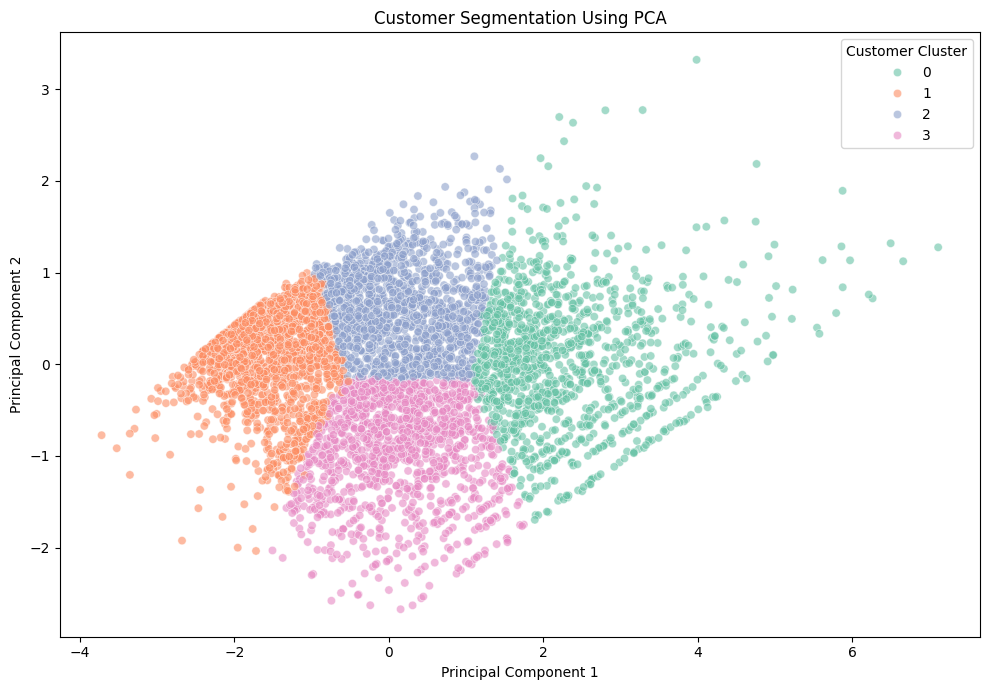

Explained variance ratio: [0.76372366 0.18766172]
Total explained variance: 95.14 %


In [ ]:
from sklearn.decomposition import PCA

# Apply PCA to standardised RFM data
pca = PCA(n_components=2)

pca_components = pca.fit_transform(rfm_scaled)

# Create PCA dataframe
pca_df = pd.DataFrame(
    pca_components,
    columns=['Principal Component 1', 'Principal Component 2'],
    index=rfm.index
)

# Add cluster labels
pca_df['Cluster'] = rfm['Cluster']

# Visualise clusters
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x='Principal Component 1',
    y='Principal Component 2',
    hue='Cluster',
    palette='Set2',
    alpha=0.6
)

plt.title('Customer Segmentation Using PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Customer Cluster')

plt.tight_layout()
plt.show()

# Explained variance
print(
    "Explained variance ratio:",
    pca.explained_variance_ratio_
)

print(
    "Total explained variance:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

In [ ]:
# Export final customer segmentation dataset

rfm.to_csv(
    'Customer_Segmentation_Results.csv',
    index=True
)

print("Final customer segmentation dataset saved successfully!")

Final customer segmentation dataset saved successfully!
